In [9]:
!pip install nltk

In [10]:
corpus=["My Name is Sneha.", "I am a %34Data @Science Student.", "I am currently in 5th Semester.", "I am pursuing. my Data Science degree from K.R. Mangalam University.", "My University is based in Sohna, Gurugram.",]
with open('corpus.txt', 'w') as f:
  f.write('\n'.join(corpus))
print('corpus.txt written:', len(corpus), 'documents')
docs=open('corpus.txt').read().splitlines()

corpus.txt written: 5 documents


In [11]:
import nltk, warnings
warnings.filterwarnings('ignore')
for pkg in ['punkt_tab', 'stopwords', 'wordnet', 'movie_reviews']:
  nltk.download(pkg, quiet=True)
print('NLP enviroment ready!')


from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer
ps, ss, lem = PorterStemmer(), SnowballStemmer('english'),WordNetLemmatizer()
words3 = ['running', 'studies', 'better', 'flies', 'meeting', 'disappointing']
print(f"{'word':<15}{'Porter':<12}{'Snowball':<12}{'Lemma(v)':<12}")
for w in words3:
  print(f"{w:<15}{ps.stem(w):<12}{ss.stem(w):<12}{lem.lemmatize(w, pos='v'):<12}")

NLP enviroment ready!
word           Porter      Snowball    Lemma(v)    
running        run         run         run         
studies        studi       studi       study       
better         better      better      better      
flies          fli         fli         fly         
meeting        meet        meet        meet        
disappointing  disappoint  disappoint  disappoint  


In [12]:
from nltk.tokenize import word_tokenize, sent_tokenize

corpus = [
    "Amazing battery life!!! lasts two hours.10/10 would reccomend :)",
    "Screen broke after 2 days,worst phone ever so less charging power.",
    "I am using this phone from last 5 yeras Excellent value for money.",
    "Average phone the camera is decent and the battery is poor.",
]
with open('corpus.txt','w')as f:
 f.write('\n'.join(corpus))
 print('corpus.txt written:',len(corpus),'document')

from nltk.corpus import stopwords
import string
stop = set(stopwords.words('english'))
toks = word_tokenize(' '.join(docs).lower())
clean = [t for t in toks if t not in stop and t not in string.punctuation]
print('Before:', len(toks),'tokens| After:', len(clean), 'tokens')
print('First 15 cleaned tokens:', clean[:15])

corpus.txt written: 4 document
Before: 44 tokens| After: 19 tokens
First 15 cleaned tokens: ['name', 'sneha', '34data', 'science', 'student', 'currently', '5th', 'semester', 'pursuing', 'data', 'science', 'degree', 'k.r', 'mangalam', 'university']


In [13]:
from nltk.tokenize import word_tokenize, sent_tokenize

docs = open('corpus.txt').read().splitlines()
text = ' '.join(docs)
sents = sent_tokenize(text)
words = word_tokenize(text)
print('Documents      :', len(docs))
print('Sentences      :', len(sents))
print('Words (tokens) :', len(words))
print('Unique tokens  :', len(set(w.lower() for w in words)))
print('Average words per document:', round(len(words)/len(docs), 1))
print("token",words)

Documents      : 4
Sentences      : 4
Words (tokens) : 53
Unique tokens  : 44
Average words per document: 13.2
token ['Amazing', 'battery', 'life', '!', '!', '!', 'lasts', 'two', 'hours.10/10', 'would', 'reccomend', ':', ')', 'Screen', 'broke', 'after', '2', 'days', ',', 'worst', 'phone', 'ever', 'so', 'less', 'charging', 'power', '.', 'I', 'am', 'using', 'this', 'phone', 'from', 'last', '5', 'yeras', 'Excellent', 'value', 'for', 'money', '.', 'Average', 'phone', 'the', 'camera', 'is', 'decent', 'and', 'the', 'battery', 'is', 'poor', '.']


In [17]:
sample = docs[2]
print('Raw text :', sample)
print('Word tokens    :', word_tokenize(sample))
print('Sentence tokens:', sent_tokenize(sample))
print('naive split()  :', sample.split()[:8], '...')

Raw text : I am using this phone from last 5 yeras Excellent value for money.
Word tokens    : ['I', 'am', 'using', 'this', 'phone', 'from', 'last', '5', 'yeras', 'Excellent', 'value', 'for', 'money', '.']
Sentence tokens: ['I am using this phone from last 5 yeras Excellent value for money.']
naive split()  : ['I', 'am', 'using', 'this', 'phone', 'from', 'last', '5'] ...


In [14]:
import re
def clean_text(t):
  t = re.sub(r'http\S+', '', t)
  t = re.sub(r'@\W+', '', t)
  t = re.sub(r'\d+', '', t)
  t = re.sub(r'[^A-Za-z\s]+', ' ', t)
  return re.sub(r'\s+', ' ', t).strip()
print('Before:', docs[1])
print('After:', clean_text(docs[1]))

Before: Screen broke after 2 days,worst phone ever so less charging power.
After: Screen broke after days worst phone ever so less charging power


10 most common words:
   science      2
   university   2
   name         1
   sneha        1
   34data       1
   student      1
   currently    1
   5th          1
   semester     1
   pursuing     1
Hapaxes (first 8): ['name', 'sneha', '34data', 'student', 'currently', '5th', 'semester', 'pursuing']


<Axes: title={'center': 'Top-20 Word Frequencies'}, xlabel='Samples', ylabel='Counts'>

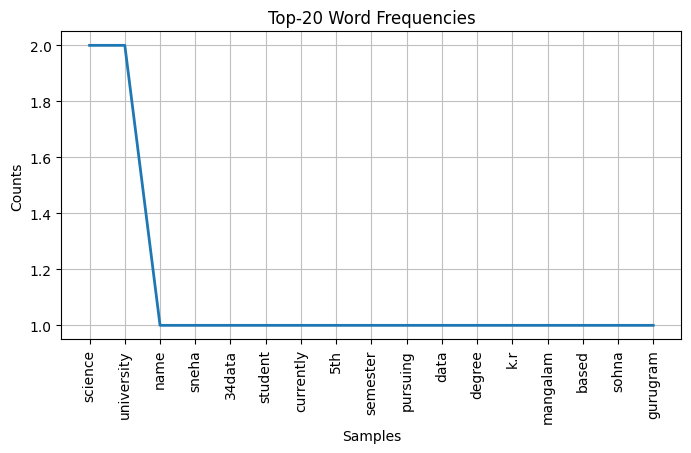

In [15]:
%matplotlib inline
from nltk import FreqDist
import matplotlib.pyplot as plt
fd = FreqDist(clean)
print('10 most common words:')
for w, cnt in fd.most_common(10):
  print(f'   {w:<12} {cnt}')
print('Hapaxes (first 8):', fd.hapaxes()[:8])
plt.figure(figsize=(8,4))
fd.plot(20, title='Top-20 Word Frequencies')

In [16]:
def preprocess(t):
    t = clean_text(t.lower())
    toks = word_tokenize(t)
    toks = [w for w in toks if w not in stop]
    return [lem.lemmatize(w, pos='v') for w in toks]

for d in docs[:2]:
    print(d, '\n ->', preprocess(d), '\n')
total = sum(len(preprocess(d)) for d in docs)
print('Corpus after full pipeline:', total, 'clean tokens from', len(docs), 'documents')

Amazing battery life!!! lasts two hours.10/10 would reccomend :) 
 -> ['amaze', 'battery', 'life', 'last', 'two', 'hours', 'would', 'reccomend'] 

Screen broke after 2 days,worst phone ever so less charging power. 
 -> ['screen', 'break', 'days', 'worst', 'phone', 'ever', 'less', 'charge', 'power'] 

Corpus after full pipeline: 30 clean tokens from 4 documents
